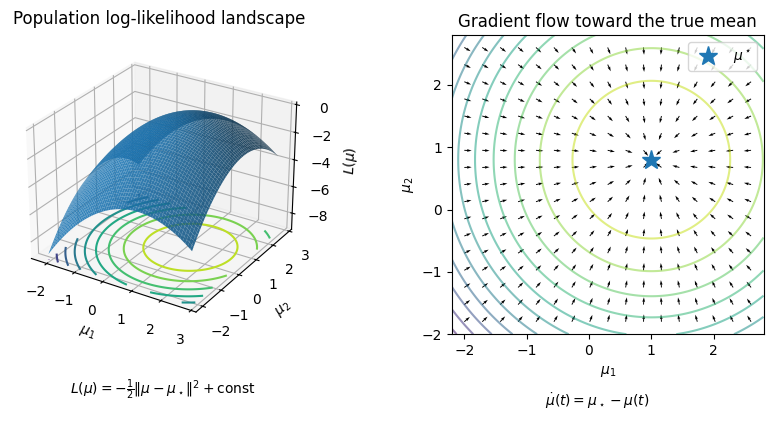

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# Bivariate classical LDA warm-up visualization:
# Left: 3D population log-likelihood surface
# Right: 2D gradient-flow vector field
#
# Population objective:
# L(mu) = -1/2 ||mu - mu_star||^2 + const
#
# Gradient flow:
# d mu(t) / dt = mu_star - mu(t)

mu_star = np.array([1.0, 0.8])

# Grid for surface, contours, and vector field
x = np.linspace(-2.2, 2.8, 180)
y = np.linspace(-2.0, 2.8, 180)
X, Y = np.meshgrid(x, y)
Z = -0.5 * ((X - mu_star[0])**2 + (Y - mu_star[1])**2)

# Coarser grid for arrows
xq = np.linspace(-2.0, 2.6, 17)
yq = np.linspace(-1.8, 2.6, 17)
Xq, Yq = np.meshgrid(xq, yq)
U = mu_star[0] - Xq
V = mu_star[1] - Yq

# Normalize arrows for readability while preserving direction
speed = np.sqrt(U**2 + V**2)
U_norm = U / (speed + 1e-9)
V_norm = V / (speed + 1e-9)

fig = plt.figure(figsize=(10.2, 4.4))
gs = fig.add_gridspec(1, 2, width_ratios=[1.08, 1.0], wspace=0.02)

# Left panel: 3D likelihood surface
ax = fig.add_subplot(gs[0, 0], projection="3d")

ax.plot_surface(
    X, Y, Z,
    rstride=3,
    cstride=3,
    linewidth=0,
    antialiased=True,
    alpha=0.9,
)

ax.contour(
    X, Y, Z,
    zdir="z",
    offset=Z.min() - 0.4,
    levels=10,
)

ax.set_title(r"Population log-likelihood landscape", pad=8)
ax.set_xlabel(r"$\mu_1$", labelpad=4)
ax.set_ylabel(r"$\mu_2$", labelpad=4)
ax.set_zlabel(r"$L(\mu)$", labelpad=4)
ax.view_init(elev=27, azim=-58)
# Put the likelihood formula below the left panel
ax.text2D(
    0.2,
    -0.2,
    r"$L(\mu)=-\frac{1}{2}\|\mu-\mu_\star\|^2+\mathrm{const}$",
    transform=ax.transAxes,
    fontsize=10,
)

# Right panel: gradient-flow vector field
ax = fig.add_subplot(gs[0, 1])

ax.contour(X, Y, Z, levels=12, alpha=0.55)

ax.quiver(
    Xq, Yq,
    U_norm, V_norm,
    angles="xy",
    scale_units="xy",
    scale=8.5,
    width=0.003,
)

ax.plot(
    mu_star[0],
    mu_star[1],
    marker="*",
    markersize=14,
    linestyle="None",
    label=r"$\mu^\star$",
)

ax.set_title(r"Gradient flow toward the true mean")
ax.set_xlabel(r"$\mu_1$")
ax.set_ylabel(r"$\mu_2$")
ax.set_aspect("equal", adjustable="box")
ax.legend(loc="upper right", frameon=True)

ax.text(
    0.3,
    -0.24,
    r"$\dot\mu(t)=\mu_\star-\mu(t)$",
    #r"$\mu(t)-\mu_\star=e^{-t}(\mu(0)-\mu_\star)$",
    transform=ax.transAxes,
    fontsize=10,
)

# Tighten margins and reduce space between panels
fig.subplots_adjust(
    left=0.03,
    right=0.9,
    top=0.9,
    bottom=0.22,
    wspace=0.02,
)

plt.savefig("lda_logl_plot.png", dpi=600, bbox_inches="tight")
plt.show()